In [1]:
import numpy as np
import jupyter
import pandas as pd
import tabulate 

# Exercise 1: Concatenate

In [8]:
df1 = pd.DataFrame([['a', 1], ['b', 2]],
                   columns=['letter', 'number'])
df2 = pd.DataFrame([['c', 1], ['d', 2]],
                   columns=['letter', 'number'])
print(pd.concat([df1, df2],ignore_index=True).to_markdown())

|    | letter   |   number |
|---:|:---------|---------:|
|  0 | a        |        1 |
|  1 | b        |        2 |
|  2 | c        |        1 |
|  3 | d        |        2 |


# Exercise 2: Merge

## 1

In [18]:
# Création des DataFrames
df1_dict = {
        'id': ['1', '2', '3', '4', '5'],
        'Feature1': ['A', 'C', 'E', 'G', 'I'],
        'Feature2': ['B', 'D', 'F', 'H', 'J']}

df1 = pd.DataFrame(df1_dict, columns = ['id', 'Feature1', 'Feature2'])

df2_dict = {
        'id': ['1', '2', '6', '7', '8'],
        'Feature1': ['K', 'M', 'O', 'Q', 'S'],
        'Feature2': ['L', 'N', 'P', 'R', 'T']}

df2 = pd.DataFrame(df2_dict, columns = ['id', 'Feature1', 'Feature2'])

# Fusion inner (intersection des identifiants)
result1 = pd.merge(df1, df2, on='id', suffixes=('_x', '_y'))

print(result1)

  id Feature1_x Feature2_x Feature1_y Feature2_y
0  1          A          B          K          L
1  2          C          D          M          N


## 2

In [22]:
# Fusion outer (union des identifiants)
result2 = pd.merge(df1, df2, on='id', how='outer', suffixes=('_df1', '_df2'))

print(result2)

  id Feature1_df1 Feature2_df1 Feature1_df2 Feature2_df2
0  1            A            B            K            L
1  2            C            D            M            N
2  3            E            F          NaN          NaN
3  4            G            H          NaN          NaN
4  5            I            J          NaN          NaN
5  6          NaN          NaN            O            P
6  7          NaN          NaN            Q            R
7  8          NaN          NaN            S            T


# Exercise 3: Merge MultiIndex

## 1

In [32]:
#generate days
all_dates = pd.date_range('2021-01-01', '2021-12-15')
business_dates = pd.bdate_range('2021-01-01', '2021-12-31')

#generate tickers
tickers = ['AAPL', 'FB', 'GE', 'AMZN', 'DAI']

#create indexs
index_alt = pd.MultiIndex.from_product([all_dates, tickers], names=['Date', 'Ticker'])
index = pd.MultiIndex.from_product([business_dates, tickers], names=['Date', 'Ticker'])

# create DFs
market_data = pd.DataFrame(index=index,
                        data=np.random.randn(len(index), 3),
                        columns=['Open','Close','Close_Adjusted'])

alternative_data = pd.DataFrame(index=index_alt,
                                data=np.random.randn(len(index_alt), 2),
                                columns=['Twitter','Reddit'])
merged = market_data.merge(alternative_data,how='left', left_index=True, right_index=True)
print(merged.head().to_markdown())

|                                            |      Open |     Close |   Close_Adjusted |   Twitter |     Reddit |
|:-------------------------------------------|----------:|----------:|-----------------:|----------:|-----------:|
| (Timestamp('2021-01-01 00:00:00'), 'AAPL') | -1.89877  | -0.566823 |        0.579011  |  1.02687  |  0.0719702 |
| (Timestamp('2021-01-01 00:00:00'), 'FB')   |  0.443235 | -0.175202 |       -0.171895  | -0.636063 | -1.04734   |
| (Timestamp('2021-01-01 00:00:00'), 'GE')   | -0.385976 |  0.520691 |        2.26409   |  0.509217 | -0.597678  |
| (Timestamp('2021-01-01 00:00:00'), 'AMZN') | -0.740108 | -0.770046 |        0.0145859 |  1.5798   | -1.60016   |
| (Timestamp('2021-01-01 00:00:00'), 'DAI')  | -1.98393  |  0.220391 |       -0.0498073 | -2.70722  |  0.469934  |


## 2

In [34]:
filled_df = merged.fillna(0)
print(filled_df.isnull().sum().sum() == 0)
print(filled_df.sum().sum() == merged.sum().sum())

True
True


# Exercise 4: Groupby Apply

## 1

In [50]:
import pandas as pd
import numpy as np

def winsorize(df, quantiles):
    """
    Remplace les valeurs extrêmes par les quantiles spécifiés.
    
    Paramètres:
        df: pd.DataFrame
        quantiles: list
            ex: [0.05, 0.95]
    """
    result = df.copy()
    for col in df.columns:
        lower_bound = np.quantile(df[col], quantiles[0])
        upper_bound = np.quantile(df[col], quantiles[1])
        result[col] = df[col].clip(lower=lower_bound, upper=upper_bound)
    
    return result

# Test de la fonction
df = pd.DataFrame(range(1, 11), columns=['sequence'])
print(winsorize(df, [0.20, 0.80]).to_markdown())

|    |   sequence |
|---:|-----------:|
|  0 |        2.8 |
|  1 |        2.8 |
|  2 |        3   |
|  3 |        4   |
|  4 |        5   |
|  5 |        6   |
|  6 |        7   |
|  7 |        8   |
|  8 |        8.2 |
|  9 |        8.2 |


## 2

In [56]:
# Création des données
groups = np.concatenate([np.ones(10), np.ones(10)+1, np.ones(10)+2, np.ones(10)+3, np.ones(10)+4])
df = pd.DataFrame(data=zip(groups, range(1, 51)), columns=["group", "sequence"])

# Application de la winsorisation par groupe
def winsorize_group(group):
    return winsorize(group[['sequence']], [0.05, 0.95])

result = df.groupby('group').apply(winsorize_group).reset_index(drop=True)

# Affichage des premiers résultats
print(result.head(11).to_markdown())

|    |   sequence |
|---:|-----------:|
|  0 |       1.45 |
|  1 |       2    |
|  2 |       3    |
|  3 |       4    |
|  4 |       5    |
|  5 |       6    |
|  6 |       7    |
|  7 |       8    |
|  8 |       9    |
|  9 |       9.55 |
| 10 |      11.45 |


C:\Users\lomao\AppData\Local\Temp\ipykernel_18084\2883333153.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  result = df.groupby('group').apply(winsorize_group).reset_index(drop=True)


# Exercise 5: Groupby Agg

In [59]:
data = {
    'value': [20.45, 22.89, 32.12, 111.22, 33.22, 100, 99.99],
    'product': ['table', 'chair', 'chair', 'mobile phone', 'table', 'mobile phone', 'table']
}

df = pd.DataFrame(data)

result = df.groupby('product').agg({'value': ['min', 'max', 'mean']})

print(result.to_markdown())

| product      |   ('value', 'min') |   ('value', 'max') |   ('value', 'mean') |
|:-------------|-------------------:|-------------------:|--------------------:|
| chair        |              22.89 |              32.12 |              27.505 |
| mobile phone |             100    |             111.22 |             105.61  |
| table        |              20.45 |              99.99 |              51.22  |


# Exercise 6: Unstack

## 1

In [71]:
business_dates = pd.bdate_range('2021-01-01', '2021-12-31')

tickers = ['AAPL', 'FB', 'GE', 'AMZN', 'DAI']

index = pd.MultiIndex.from_product([business_dates, tickers], names=['Date', 'Ticker'])

market_data = pd.DataFrame(index=index,
                        data=np.random.randn(len(index), 1),
                        columns=['Prediction'])
unstacked= market_data.unstack(level='Ticker')
print(unstacked.head(3).to_markdown())

| Date                |   ('Prediction', 'AAPL') |   ('Prediction', 'AMZN') |   ('Prediction', 'DAI') |   ('Prediction', 'FB') |   ('Prediction', 'GE') |
|:--------------------|-------------------------:|-------------------------:|------------------------:|-----------------------:|-----------------------:|
| 2021-01-01 00:00:00 |                 1.3375   |                -0.816692 |                0.606663 |              -0.674033 |               0.126166 |
| 2021-01-04 00:00:00 |                 1.04886  |                -0.375644 |                0.190368 |               2.97243  |              -1.72947  |
| 2021-01-05 00:00:00 |                -0.907871 |                -1.46573  |               -0.564674 |               1.5519   |              -2.34506  |


## 2

<Axes: title={'center': 'Predicted Scores'}, xlabel='Date'>

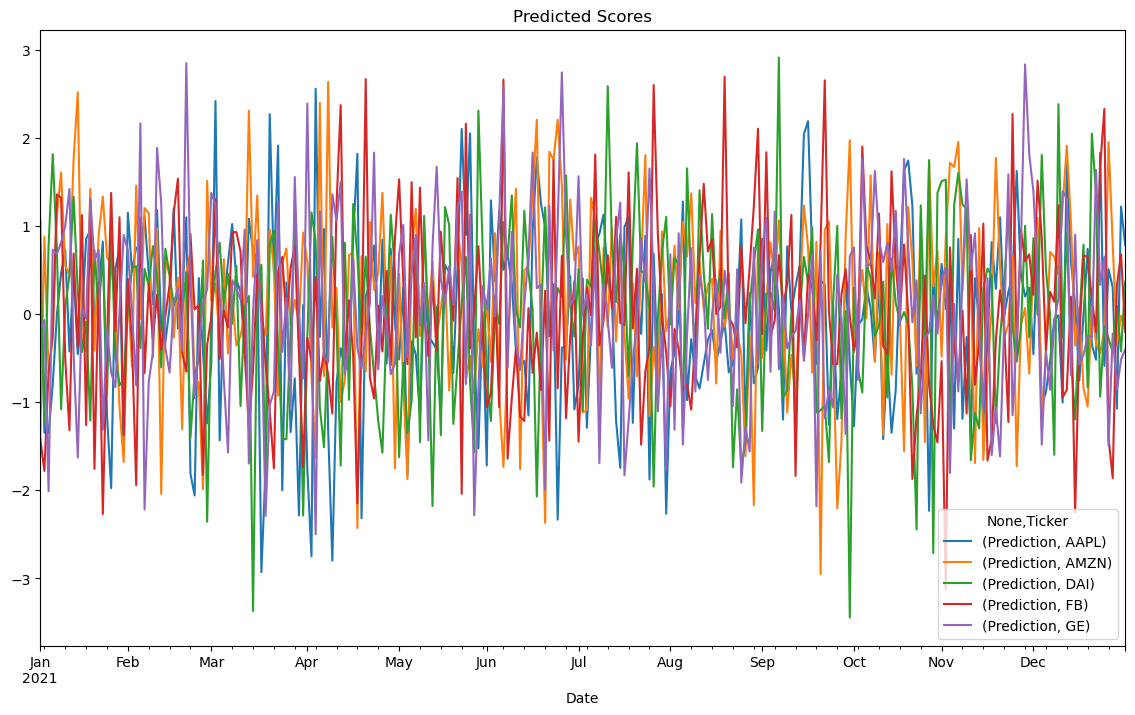

In [67]:
unstacked.plot(title='Predicted Scores',figsize=(14, 8))